# Comptage de mots : Python simple vs pseudo-MapReduce vs Hadoop MapReduce
**Objectif :** On implémente trois méthodes de comptage des occurrences de mots et sur les mêmes fichiers, de tailles croissantes.
On génére les données nous-même en utilisant la répétition et la duplication.

# Comptage de mots : Python, pseudo-MapReduce, Hadoop MapReduce et Spark

## Objectif
Le comptage de mots (*word count*) consiste à calculer, pour chaque mot distinct d'un texte, son nombre
d'occurrences. C'est l'exemple de référence du traitement de données massives : le calcul est simple,
mais sur de très gros volumes, un seul ordinateur ne suffit plus, et il faut répartir le travail.

Nous comparons cinq implémentations sur les **mêmes fichiers**, de taille croissante :
1. **Python simple** : un dictionnaire, un seul processus ;
2. **pseudo-MapReduce en Python** : on reproduit à la main les étapes du modèle MapReduce ;
3. **Hadoop MapReduce** : l'implémentation de référence du modèle, sur un cluster (pseudo-)distribué ;
4. **Spark RDD** et 5. **Spark DataFrame** : le successeur de Hadoop MapReduce, qui calcule en mémoire.

## Le modèle MapReduce
MapReduce est un modèle de programmation proposé par Google (2004) pour traiter de grands volumes de
données sur un ensemble de machines. Le programmeur n'écrit que deux fonctions ; le framework se charge
du découpage des données, de la distribution du calcul, des transferts réseau et des pannes.

Les données circulent sous forme de **paires clé/valeur** `(k, v)` à travers trois phases :

| Phase | Rôle | Entrée → Sortie | Pour le comptage de mots |
|---|---|---|---|
| **Map** | appliquée indépendamment à chaque morceau de l'entrée ; c'est la partie parallélisable | un enregistrement → liste de `(k, v)` | une ligne → `(mot, 1)` pour chaque mot |
| **Shuffle** (et tri) | effectuée par le framework : regroupe toutes les valeurs d'une même clé et les envoie au même reducer | toutes les `(k, v)` → `(k, [v1, v2, …])` | `(chat, [1, 1, 1])` |
| **Reduce** | agrège la liste de valeurs de chaque clé | `(k, [v…])` → `(k, résultat)` | `(chat, 3)` |

**Exemple** sur deux lignes `"chat chien"` et `"chat chat"` :
- *map* : `(chat,1) (chien,1)` et `(chat,1) (chat,1)`
- *shuffle* : `chat → [1, 1, 1]`, `chien → [1]`
- *reduce* : `chat → 3`, `chien → 1`

Une optimisation classique est le **combiner** : un « mini-reduce » exécuté localement après chaque map
(`(chat,1),(chat,1)` → `(chat,2)`), qui réduit le volume de données à transférer pendant le shuffle.

Le **shuffle** est généralement l'étape la plus coûteuse : dans un vrai cluster, c'est là que les données
traversent le réseau d'une machine à l'autre.

## Génération des fichiers de test

Comme demandé, on construit les fichiers en deux temps :
1. un **fichier de base** de N = 10 000 lignes, contenant chacune un mot tiré au hasard (avec remise)
   dans un vocabulaire de 20 mots ;
2. des **fichiers dupliqués** de m × N lignes, obtenus en recopiant m fois le fichier de base,
   pour m ∈ {1, 10, 50, 100, 200, 500}, soit de 10 000 à 5 000 000 de lignes (0,07 à 36,6 Mo).

**Pourquoi ce procédé ?**
- La graine aléatoire est fixée (`seed=42`) : les fichiers sont **reproductibles**, toute personne qui
  relance le notebook obtient exactement les mêmes données.
- La duplication rend les résultats **vérifiables** : si un mot apparaît c fois dans le fichier de base,
  il doit apparaître exactement m × c fois dans le fichier m. On s'en sert dans les tests.
- Seule la **taille** varie d'un fichier à l'autre (même vocabulaire, même distribution) : les écarts de
  temps mesurés viennent donc uniquement du volume de données.

On s'arrête à m = 500, car la version pseudo-MapReduce garde toutes ses données intermédiaires en mémoire
(voir plus bas).

## Environnement
- Windows + Docker Desktop (moteur WSL 2) ; Python et Jupyter côté Windows.
- Hadoop : image officielle `apache/hadoop:3`, cluster pseudo-distribué de 4 conteneurs
  (NameNode, DataNode, ResourceManager, NodeManager), réplication HDFS = 1.
- Données : générées par le notebook (vocabulaire de 20 mots, N = 10 000 lignes, graine fixe).

In [1]:
# On génère les fichiers 

import os
import random

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

VOCABULAIRE = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne",
               "livre", "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture",
               "riviere", "nuage", "foret", "ville", "pomme"]

def generer_base(n, chemin, seed=42):
    """Génère un fichier de n lignes, un mot aléatoire (avec répétition) par ligne."""
    rng = random.Random(seed)              
    mots = rng.choices(VOCABULAIRE, k=n)
    with open(chemin, "w", encoding="utf-8") as f:
        f.write("\n".join(mots) + "\n")
    return chemin

def generer_duplique(chemin_base, m, chemin_sortie):
    """Génère un fichier de m×N lignes en dupliquant m fois les N lignes du fichier de base."""
    with open(chemin_base, "r", encoding="utf-8") as f:
        bloc = f.read()
    with open(chemin_sortie, "w", encoding="utf-8") as f:
        for _ in range(m):
            f.write(bloc)
    return chemin_sortie

N = 10_000
base = generer_base(N, os.path.join(DATA_DIR, "base.txt"))

M_VALUES = [1, 10, 50, 100, 200, 500]
fichiers = {}
for m in M_VALUES:
    chemin = os.path.join(DATA_DIR, f"mots_m{m}.txt")
    generer_duplique(base, m, chemin)
    fichiers[m] = chemin
    taille_mo = os.path.getsize(chemin) / 1e6
    print(f"m={m:>4} -> {m*N:>10,} lignes, {taille_mo:8.2f} Mo  ({chemin})")

m=   1 ->     10,000 lignes,     0.07 Mo  (data\mots_m1.txt)
m=  10 ->    100,000 lignes,     0.73 Mo  (data\mots_m10.txt)
m=  50 ->    500,000 lignes,     3.66 Mo  (data\mots_m50.txt)
m= 100 ->  1,000,000 lignes,     7.32 Mo  (data\mots_m100.txt)
m= 200 ->  2,000,000 lignes,    14.64 Mo  (data\mots_m200.txt)
m= 500 ->  5,000,000 lignes,    36.59 Mo  (data\mots_m500.txt)


## Version 1 : Python simple

**Principe.** On lit tout le fichier en une seule fois (`f.read()`), on le découpe en mots avec
`split()` (qui coupe sur les espaces et les retours à la ligne), puis on parcourt les mots en
incrémentant un compteur dans un dictionnaire : `compteur[mot] = compteur.get(mot, 0) + 1`.

**Complexité.**
- Temps : **O(n)** pour n mots, car chaque accès au dictionnaire (table de hachage) coûte O(1) en moyenne.
- Mémoire : le texte entier et la liste de tous les mots sont chargés en mémoire, plus un dictionnaire
  de taille égale au nombre de mots *distincts* (ici 20).

**Limite.** Tout se passe dans un seul processus, sur un seul cœur et une seule machine : si le fichier
ne tient pas en mémoire, cette méthode ne fonctionne plus.

In [2]:
def compter_v1(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

res = compter_v1(fichiers[1])
for mot, nb in sorted(res.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{mot} : {nb}")

jardin : 540
montagne : 535
arbre : 535
chien : 530
oiseau : 526


## Version 2 : pseudo-MapReduce en Python

On reproduit **localement** les trois phases du modèle MapReduce (définies dans l'introduction), avec une
fonction Python pour chacune :

**1. `mapper(ligne)` : phase Map.**
Reçoit une ligne et renvoie une liste de paires `(mot, 1)`, une par mot. Chaque appel est indépendant des
autres : dans un vrai système, les lignes pourraient être traitées sur des machines différentes.
`"chat chien"` → `[("chat", 1), ("chien", 1)]`.
Toutes ces paires sont accumulées dans une liste `mapped` (5 millions de paires pour le plus gros fichier).

**2. `shuffle(mapped_data)` : phase de regroupement.**
Parcourt toutes les paires et regroupe les valeurs par clé dans un `defaultdict(list)` :
`[("chat",1), ("chien",1), ("chat",1)]` → `{"chat": [1, 1], "chien": [1]}`.
Dans Hadoop, c'est le framework qui fait cette étape (tri + transfert réseau vers les reducers) ;
ici c'est un simple dictionnaire en mémoire.

**3. `reducer(grouped_data)` : phase Reduce.**
Pour chaque clé, additionne sa liste de valeurs : `{"chat": [1, 1]}` → `{"chat": 2}`.

**Ce que cette version montre, et ce qu'elle ne montre pas.**
- Elle rend visible la **structure** d'un programme MapReduce : on comprend ce que fait chaque étape.
- Elle n'en a pas les **bénéfices** : tout s'exécute séquentiellement dans un seul processus, sans
  parallélisme ni distribution.
- Elle a en revanche le **coût** du modèle : chaque mot produit un tuple `(mot, 1)` stocké en mémoire,
  puis recopié dans une liste au moment du shuffle. On s'attend donc à ce qu'elle soit plus lente et plus
  gourmande en mémoire que la V1, ce que nous vérifierons.

In [3]:
from collections import defaultdict

def mapper(ligne):
    # MAP : une ligne -> liste de paires (clé, valeur) = (mot, 1)
    # strip() retire le retour à la ligne, split() découpe sur les espaces
    return [(mot, 1) for mot in ligne.strip().split()]

def shuffle(mapped_data):
    # SHUFFLE : regroupe toutes les valeurs ayant la même clé
    # defaultdict(list) crée automatiquement une liste vide pour chaque nouvelle clé
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)          # {"chat": [1, 1, 1], "chien": [1], ...}
    return grouped

def reducer(grouped_data):
    # REDUCE : agrège la liste de valeurs de chaque clé (ici, une somme)
    return {mot: sum(valeurs) for mot, valeurs in grouped_data.items()}

def compter_v2(fichier):
    mapped = []                             # toutes les paires (mot, 1) du fichier, en mémoire
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:                     # lecture ligne par ligne
            mapped.extend(mapper(ligne))    # phase map appliquée à chaque ligne 
    return reducer(shuffle(mapped))         # shuffle puis reduce sur l'ensemble

res2 = compter_v2(fichiers[1])
for mot, nb in sorted(res2.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{mot} : {nb}")                 # les 5 mots les plus fréquents

jardin : 540
montagne : 535
arbre : 535
chien : 530
oiseau : 526


## Tests de validité

Avant de comparer des temps, il faut s'assurer que toutes les méthodes calculent **le même résultat**,
et que ce résultat est **correct**. On utilise trois vérifications complémentaires :

1. **Comparaison à une référence indépendante.** `collections.Counter` est l'outil standard de Python
   pour compter des éléments. Si V1 et V2 donnent exactement le même dictionnaire que lui, elles sont correctes.
2. **Conservation du nombre total de mots.** La somme de tous les comptes doit valoir m × N.
   Cela détecte un mot perdu ou compté deux fois.
3. **Cohérence avec la duplication.** Pour chaque mot, le compte dans le fichier m doit être m fois le
   compte dans le fichier de base. Cela vérifie à la fois les méthodes et le générateur.

Les tests utilisent des `assert` : si une condition est fausse, l'exécution s'arrête avec un message d'erreur.
Les mêmes vérifications sont refaites plus loin pour Hadoop et Spark, et à chaque mesure du benchmark.

In [4]:
from collections import Counter

def reference(fichier):
    with open(fichier, encoding="utf-8") as f:
        return dict(Counter(f.read().split()))

ref_base = reference(fichiers[1])

for m in [1, 10, 50]:                      
    ref = reference(fichiers[m])
    r1, r2 = compter_v1(fichiers[m]), compter_v2(fichiers[m])
    assert r1 == ref, f"V1 incorrecte pour m={m}"
    assert r2 == ref, f"V2 incorrecte pour m={m}"
    assert sum(r1.values()) == m * N, "nombre total de mots incorrect"
    assert all(r1[mot] == m * ref_base[mot] for mot in ref_base), "duplication incorrecte"
    print(f"m={m:>3} : OK  ({len(r1)} mots distincts, {sum(r1.values()):,} mots au total)")

print("Tous les tests passent.")

m=  1 : OK  (20 mots distincts, 10,000 mots au total)
m= 10 : OK  (20 mots distincts, 100,000 mots au total)
m= 50 : OK  (20 mots distincts, 500,000 mots au total)
Tous les tests passent.


## Version 3 : Hadoop MapReduce

Hadoop est l'implémentation open source du modèle MapReduce. Il repose sur deux composants :

**HDFS (Hadoop Distributed File System)** : le stockage.
- Les fichiers sont découpés en **blocs** de 128 Mo, répartis sur plusieurs machines.
- Le **NameNode** conserve les métadonnées : quels fichiers existent, et où se trouve chacun de leurs blocs.
- Les **DataNodes** stockent les blocs eux-mêmes.
- Chaque bloc est normalement copié sur 3 machines (**réplication**), pour survivre aux pannes ;
  ici, avec un seul DataNode, la réplication vaut 1.

**YARN (Yet Another Resource Negotiator)** : l'exécution.
- Le **ResourceManager** gère les ressources (mémoire, CPU) de tout le cluster et accepte les jobs.
- Les **NodeManagers** (un par machine) lancent les tâches dans des **conteneurs** (des processus Java isolés).
- Pour chaque job, un **ApplicationMaster** est démarré : il demande des conteneurs et y lance les
  tâches map, puis les tâches reduce.

**Déroulement d'un job wordcount :**
1. le fichier est copié dans HDFS (`hdfs dfs -put`) ;
2. le job est soumis au ResourceManager (`hadoop jar … wordcount`) ;
3. YARN démarre l'ApplicationMaster, qui lance **un map par bloc** du fichier d'entrée ;
4. chaque map écrit ses paires `(mot, 1)` sur le disque local, triées par clé (avec un combiner) ;
5. le shuffle transfère ces données vers le(s) reducer(s), qui écrivent le résultat dans HDFS
   (`part-r-00000`).

**Notre installation.** Un vrai cluster comporte plusieurs machines. Faute de cluster, on utilise un
cluster **pseudo-distribué** : les 4 démons (NameNode, DataNode, ResourceManager, NodeManager) tournent
dans 4 conteneurs **Docker** sur la même machine, avec l'image officielle `apache/hadoop:3`.
Docker évite d'installer Hadoop sous Windows, ce qui est difficile. L'architecture et les commandes
sont celles d'un vrai cluster.

In [5]:
# Configuration du cluster 

os.makedirs("hadoop", exist_ok=True)

docker_compose = """services:
  namenode:
    image: apache/hadoop:3
    hostname: namenode
    command: ["hdfs", "namenode"]
    ports: ["9870:9870"]
    env_file: [./config]
    environment:
      ENSURE_NAMENODE_DIR: "/tmp/hadoop-root/dfs/name"
    volumes:
      - ../data:/data
  datanode:
    image: apache/hadoop:3
    command: ["hdfs", "datanode"]
    env_file: [./config]
  resourcemanager:
    image: apache/hadoop:3
    hostname: resourcemanager
    command: ["yarn", "resourcemanager"]
    ports: ["8088:8088"]
    env_file: [./config]
  nodemanager:
    image: apache/hadoop:3
    command: ["yarn", "nodemanager"]
    env_file: [./config]
"""

config = """CORE-SITE.XML_fs.default.name=hdfs://namenode
CORE-SITE.XML_fs.defaultFS=hdfs://namenode
HDFS-SITE.XML_dfs.namenode.rpc-address=namenode:8020
HDFS-SITE.XML_dfs.replication=1
MAPRED-SITE.XML_mapreduce.framework.name=yarn
MAPRED-SITE.XML_yarn.app.mapreduce.am.env=HADOOP_MAPRED_HOME=/opt/hadoop
MAPRED-SITE.XML_mapreduce.map.env=HADOOP_MAPRED_HOME=/opt/hadoop
MAPRED-SITE.XML_mapreduce.reduce.env=HADOOP_MAPRED_HOME=/opt/hadoop
YARN-SITE.XML_yarn.resourcemanager.hostname=resourcemanager
YARN-SITE.XML_yarn.nodemanager.pmem-check-enabled=false
YARN-SITE.XML_yarn.nodemanager.vmem-check-enabled=false
YARN-SITE.XML_yarn.nodemanager.aux-services=mapreduce_shuffle
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.maximum-am-resource-percent=0.5
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.queues=default
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.capacity=100
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.maximum-capacity=100
"""

with open("hadoop/docker-compose.yaml", "w", newline="\n") as f:
    f.write(docker_compose)
with open("hadoop/config", "w", newline="\n") as f:
    f.write(config)
print("Fichiers écrits :", os.listdir("hadoop"))

Fichiers écrits : ['config', 'docker-compose.yaml']


**Ce que contient la configuration écrite ci-dessus.**
- `docker-compose.yaml` décrit les 4 conteneurs : leur image, la commande qui démarre chaque démon
  (`hdfs namenode`, `yarn resourcemanager`, …), les ports exposés pour les interfaces web
  (9870 pour HDFS, 8088 pour YARN), et le **montage** du dossier `data/` de Windows dans le NameNode
  sous `/data`, pour qu'il puisse y lire nos fichiers.
- `config` contient les paramètres Hadoop, que l'image convertit en fichiers XML au démarrage :
  - `fs.defaultFS=hdfs://namenode` : le système de fichiers par défaut est HDFS, géré par le conteneur `namenode` ;
  - `dfs.replication=1` : une seule copie de chaque bloc (il n'y a qu'un DataNode) ;
  - `mapreduce.framework.name=yarn` : les jobs MapReduce sont exécutés par YARN ;
  - `yarn.nodemanager.aux-services=mapreduce_shuffle` : active le service qui réalise le shuffle ;
  - `HADOOP_MAPRED_HOME=/opt/hadoop` : indique aux tâches où trouver les bibliothèques MapReduce.

Le cluster est ensuite démarré dans un terminal avec `docker compose up -d`. On vérifie avec
`hdfs dfsadmin -report` que HDFS voit bien son DataNode (« Live datanodes (1) »).

### Pilotage de Hadoop depuis le notebook

Hadoop tourne dans des conteneurs Docker, et non dans Python. « Piloter » Hadoop depuis le notebook signifie
**envoyer depuis Python les mêmes commandes qu'on taperait dans un terminal**, puis récupérer leur
résultat pour l'utiliser dans le notebook (mesurer un temps, vérifier les comptes).
Cela permet de garder toute l'expérience reproductible dans un seul notebook.

**Chaîne d'exécution d'une commande :**

notebook Python → `subprocess.run` → `docker compose exec namenode` → `bash -c "…"` → commande Hadoop

- `subprocess.run([...])` lance un programme externe depuis Python et attend qu'il se termine ;
  `capture_output=True` récupère ce qu'il affiche, pour pouvoir l'analyser.
- `docker compose exec -T namenode` exécute une commande **à l'intérieur** du conteneur NameNode, où les
  outils Hadoop sont installés. L'option `-T` désactive le terminal interactif, inutile depuis un programme.
- `bash -c "…"` permet d'utiliser `&&` et le joker `*` dans le nom du jar.

**Rôle de chaque fonction :**

| Fonction | Ce qu'elle fait | Commandes Hadoop utilisées |
|---|---|---|
| `hadoop_exec(cmd)` | exécute une commande dans le NameNode, renvoie sa sortie ou lève une erreur | n'importe laquelle |
| `charger_dans_hdfs(m)` | crée le dossier d'entrée dans HDFS et y copie `mots_m{m}.txt` depuis `/data` ; mesure la durée | `hdfs dfs -mkdir -p`, `hdfs dfs -put -f` |
| `compter_v3(m)` | supprime l'ancien dossier de sortie (Hadoop refuse d'écraser un résultat existant), lance le job wordcount et mesure sa durée, puis lit le résultat dans HDFS et le convertit en dictionnaire Python | `hdfs dfs -rm -r -f`, `hadoop jar … wordcount`, `hdfs dfs -cat` |

Le résultat du job est un fichier texte `part-r-00000` contenant une ligne `mot<TAB>compte` par mot.
On le découpe sur la tabulation pour obtenir le même format `{mot: compte}` que V1 et V2, ce qui permet
de comparer directement les résultats.

**Ce qu'on chronomètre :** uniquement l'exécution du job (`hadoop jar …`). La copie dans HDFS est mesurée
à part, car dans un usage réel les données sont déjà stockées dans HDFS.

In [6]:
# Pilotage de Hadoop depuis le notebook

import subprocess
import time

def hadoop_exec(commande):
    """Exécute une commande dans le conteneur NameNode et renvoie sa sortie."""
    r = subprocess.run(
        ["docker", "compose", "exec", "-T", "namenode", "bash", "-c", commande],
        cwd="hadoop", capture_output=True, text=True, encoding="utf-8"
    )
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
    return r.stdout

JAR = "/opt/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar"
HDFS_IN, HDFS_OUT = "/user/hadoop/input", "/user/hadoop/output"

def charger_dans_hdfs(m):
    """Copie data/mots_m{m}.txt dans HDFS et renvoie la durée de la copie."""
    t0 = time.perf_counter()
    hadoop_exec(f"hdfs dfs -mkdir -p {HDFS_IN} && "
                f"hdfs dfs -put -f /data/mots_m{m}.txt {HDFS_IN}/")
    return time.perf_counter() - t0

def compter_v3(m):
    """Lance le job wordcount Hadoop sur mots_m{m}.txt et renvoie (résultats, durée du job)."""
    sortie = f"{HDFS_OUT}_m{m}"
    hadoop_exec(f"hdfs dfs -rm -r -f {sortie}")           
    t0 = time.perf_counter()
    hadoop_exec(f"hadoop jar {JAR} wordcount {HDFS_IN}/mots_m{m}.txt {sortie}")
    duree = time.perf_counter() - t0
    texte = hadoop_exec(f"hdfs dfs -cat {sortie}/part-r-*")
    resultats = {}
    for ligne in texte.strip().splitlines():
        mot, nb = ligne.split("\t")
        resultats[mot] = int(nb)
    return resultats, duree

In [7]:
# premier job et test 

t_put = charger_dans_hdfs(1)
r3, t_job = compter_v3(1)

print(f"Copie dans HDFS : {t_put:.2f} s   ,   Job wordcount : {t_job:.2f} s")
for mot, nb in sorted(r3.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"{mot} : {nb}")

assert r3 == reference(fichiers[1]), "Hadoop donne des comptes différents."
print("Hadoop donne exactement les mêmes comptes que V1 et V2.")

Copie dans HDFS : 4.37 s   ,   Job wordcount : 18.04 s
jardin : 540
arbre : 535
montagne : 535
chien : 530
oiseau : 526
Hadoop donne exactement les mêmes comptes que V1 et V2.


Les 3 méthodes donnent excatement les mêmes comptes. Le job Hadoop a pris 22,8 s contre quelques millisecondes en Python, ce qui illustre bien la latence de démarrage. 

## Comparaison des performances : protocole

- **Mêmes données** : chaque méthode est exécutée sur les 6 mêmes fichiers (m = 1 à 500).
- **Mesure du temps** : `time.perf_counter()`, l'horloge la plus précise de Python. On mesure le temps
  réel écoulé (*wall-clock*), c'est-à-dire ce que perçoit l'utilisateur.
- **Répétitions** : V1, V2 et Spark sont exécutées 3 fois par fichier, et on garde la **médiane**.
  La médiane est moins sensible qu'une moyenne à une exécution ralentie par une autre activité de la machine.
  Hadoop est exécuté une seule fois par fichier, car chaque job dure près de 20 s.
- **Vérification** : à chaque mesure, on vérifie avec `assert` que les comptes sont corrects ;
  une méthode rapide mais fausse ne serait pas retenue.
- Les résultats sont enregistrés dans `resultats_benchmark.csv`.

In [8]:
# benchmark 

import statistics
import pandas as pd

def chrono(fonction, fichier, repetitions=3):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        res = fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps), res

lignes = []
for m in M_VALUES:
    ref = reference(fichiers[m])
    t1, r1 = chrono(compter_v1, fichiers[m])
    t2, r2 = chrono(compter_v2, fichiers[m])
    t_put = charger_dans_hdfs(m)
    r3, t3 = compter_v3(m)
    assert r1 == ref and r2 == ref and r3 == ref, f"résultats différents pour m={m}"
    lignes.append({"m": m, "lignes": m * N,
                   "taille (Mo)": round(os.path.getsize(fichiers[m]) / 1e6, 2),
                   "V1 Python (s)": round(t1, 4),
                   "V2 pseudo-MR (s)": round(t2, 4),
                   "V3 Hadoop job (s)": round(t3, 2),
                   "Copie HDFS (s)": round(t_put, 2)})
    print(f"m={m:>4} terminé  ->  V1 {t1:.3f}s | V2 {t2:.3f}s | Hadoop {t3:.1f}s")

df = pd.DataFrame(lignes)
df.to_csv("resultats_benchmark.csv", index=False)
df

m=   1 terminé  ->  V1 0.002s | V2 0.006s | Hadoop 17.7s
m=  10 terminé  ->  V1 0.020s | V2 0.053s | Hadoop 16.7s
m=  50 terminé  ->  V1 0.104s | V2 0.267s | Hadoop 17.7s
m= 100 terminé  ->  V1 0.222s | V2 0.548s | Hadoop 16.7s
m= 200 terminé  ->  V1 0.434s | V2 1.101s | Hadoop 18.7s
m= 500 terminé  ->  V1 1.068s | V2 2.768s | Hadoop 19.8s


,m,lignes,taille (Mo),V1 Python (s),V2 pseudo-MR (s),V3 Hadoop job (s),Copie HDFS (s)
0,1,10000,0.07,0.0021,0.0057,17.72,3.13
1,10,100000,0.73,0.0196,0.0530,16.69,3.12
2,50,500000,3.66,0.1036,0.2668,17.72,3.22
3,100,1000000,7.32,0.2217,0.5481,16.66,3.46
4,200,2000000,14.64,0.4338,1.1009,18.73,3.85
5,500,5000000,36.59,1.0676,2.7681,19.79,5.08


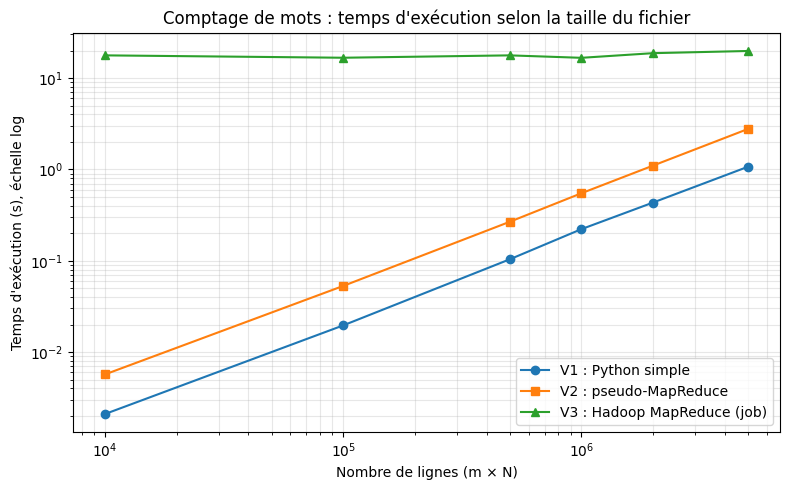

In [9]:
# graphique 

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df["lignes"], df["V1 Python (s)"], "o-", label="V1 : Python simple")
ax.plot(df["lignes"], df["V2 pseudo-MR (s)"], "s-", label="V2 : pseudo-MapReduce")
ax.plot(df["lignes"], df["V3 Hadoop job (s)"], "^-", label="V3 : Hadoop MapReduce (job)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de lignes (m × N)")
ax.set_ylabel("Temps d'exécution (s), échelle log")
ax.set_title("Comptage de mots : temps d'exécution selon la taille du fichier")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("comparaison_temps.png", dpi=150)
plt.show()

### Lecture de la figure : temps d'exécution selon la taille du fichier

**Comment lire ce graphique.** Les deux axes sont en **échelle logarithmique** : chaque graduation
multiplie la valeur par 10. Cette échelle est nécessaire, car les tailles vont de 10⁴ à 5·10⁶ lignes et
les temps de 0,002 s à 20 s. Sur une échelle log-log :
- une droite de **pente 1** signifie un temps **proportionnel** à la taille (si la taille est multipliée
  par 10, le temps aussi) ;
- une courbe **horizontale** signifie un temps **constant**, indépendant de la taille ;
- un **écart vertical constant** entre deux droites parallèles signifie un **rapport constant** entre
  les deux méthodes.

**Ce qu'on observe.**
- **V1 (bleu) et V2 (orange)** sont deux droites parallèles de pente ≈ 1 : leur temps est proportionnel
  au nombre de lignes (complexité linéaire O(n)). L'écart vertical constant montre que V2 est toujours
  ~2,6 fois plus lente que V1 : c'est le coût de la création et du regroupement des paires `(mot, 1)`.
  Ordre de grandeur pour V1 : ~0,21 s par million de lignes.
- **Hadoop (vert)** est quasi horizontal, entre 17 et 20 s : son temps ne dépend presque pas de la taille.
  Il est dominé par un **coût fixe** de démarrage (soumission du job à YARN, lancement de l'ApplicationMaster
  et des conteneurs Java), payé même pour 10 000 lignes. Le temps de traitement des données elles-mêmes ne
  devient visible qu'à droite, où la courbe remonte légèrement.
- **Aucun croisement n'est visible** entre Hadoop et les versions Python dans l'intervalle testé : même sur
  5 millions de lignes, Hadoop est ~18 fois plus lent que V1. Sur une seule machine, avec des fichiers plus
  petits qu'un bloc HDFS (un seul map), Hadoop n'a aucun parallélisme à offrir pour compenser sa latence.

**Conclusion de la figure.** Pour des volumes qui tiennent sur une machine, la méthode la plus simple est
la plus rapide. Le coût fixe de Hadoop ne se justifie que lorsque les données sont trop volumineuses pour
une seule machine.

In [10]:
# mémoire de V1 vs V2

import tracemalloc

def pic_memoire(fonction, fichier):
    tracemalloc.start()
    fonction(fichier)
    _, pic = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pic / 1e6

for m in [10, 100]:
    print(f"m={m:>3} : V1 pic = {pic_memoire(compter_v1, fichiers[m]):7.1f} Mo   |   "
          f"V2 pic = {pic_memoire(compter_v2, fichiers[m]):7.1f} Mo")

m= 10 : V1 pic =     6.1 Mo   |   V2 pic =    11.9 Mo
m=100 : V1 pic =    61.1 Mo   |   V2 pic =   119.1 Mo


### Lecture de la mesure mémoire

`tracemalloc` est un module standard de Python qui enregistre les allocations mémoire faites par Python ;
on en retient le **pic**, c'est-à-dire la mémoire maximale utilisée pendant le comptage.

| | V1 | V2 |
|---|---|---|
| 100 000 lignes | 6,1 Mo | 11,8 Mo |
| 1 000 000 lignes | 61,1 Mo | 119,1 Mo |

- La mémoire est **proportionnelle à la taille** du fichier pour les deux méthodes (×10 lignes → ×10 mémoire),
  car toutes les deux gardent tous les mots en mémoire.
- V2 consomme **~2 fois plus** que V1 : en plus de la liste des mots, elle stocke un tuple `(mot, 1)` par mot,
  puis les listes de valeurs du shuffle.
- Extrapolation : pour 1 milliard de lignes, V2 demanderait ~120 Go, ce qu'aucun ordinateur personnel ne
  possède. C'est précisément le problème que résout la distribution : Hadoop découpe les données en blocs
  traités séparément, et écrit ses résultats intermédiaires sur disque plutôt que de tout garder en mémoire.

## Version 4 : Apache Spark (PySpark)

Spark est un moteur de calcul distribué conçu pour remplacer Hadoop MapReduce. Il reprend le même modèle
(map → shuffle → reduce) mais en corrige les principaux défauts :
- les données intermédiaires restent **en mémoire** au lieu d'être écrites sur disque entre chaque étape ;
- les tâches sont lancées comme des **threads** dans une JVM déjà démarrée, au lieu de nouveaux conteneurs
  YARN pour chaque job, d'où une latence bien plus faible.

**Notions clés.**
- **Partition** : un morceau des données. Chaque partition est traitée par une **tâche**, et les tâches
  s'exécutent en parallèle sur les cœurs disponibles. Plus il y a de partitions (jusqu'au nombre de
  cœurs), plus le parallélisme est grand.
- **Transformations et actions.** Les transformations (`flatMap`, `map`, `reduceByKey`, `groupBy`…)
  ne calculent rien immédiatement : Spark se contente de construire un plan d'exécution (un graphe, ou DAG).
  C'est l'**évaluation paresseuse** (*lazy evaluation*). Le calcul n'est réellement lancé qu'au moment d'une
  **action** (`collect()`, `count()`…), ce qui permet à Spark d'optimiser le plan dans son ensemble.
- **Mode local** (`local[*]`) : le « cluster » est un seul processus JVM qui utilise tous les cœurs de la
  machine (8 ici). Le même code fonctionnerait sans modification sur un vrai cluster.
- **PySpark** : l'interface Python de Spark. Le moteur reste écrit en Scala et s'exécute dans la JVM ;
  Python communique avec lui.

In [11]:
# Démarrage de Spark
import os, sys

JAVA8 = r"C:\Program Files\Java\jre1.8.0_461"     # adapte si le dossier porte un autre nom
assert os.path.exists(os.path.join(JAVA8, "bin", "java.exe")), f"Java introuvable dans {JAVA8}"

os.environ["JAVA_HOME"] = JAVA8
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .master("local[*]")
         .appName("ComptageMots")
         .config("spark.driver.host", "localhost")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.driver.memory", "2g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version, "| parallélisme :", sc.defaultParallelism, "cœurs")
print("Test :", sc.parallelize(range(100)).map(lambda x: x * 2).sum())

Spark 3.5.9 | parallélisme : 8 cœurs
Test : 9900


In [12]:
# Spark RDD

def uri(fichier):
    """Chemin Windows -> URI que Spark comprend (file:///C:/...)."""
    return "file:///" + os.path.abspath(fichier).replace("\\", "/")

def compter_spark_rdd(fichier):
    return dict(
        sc.textFile(uri(fichier))
          .flatMap(lambda ligne: ligne.split())    # map : ligne -> mots
          .map(lambda mot: (mot, 1))               # map : mot -> (mot, 1)
          .reduceByKey(lambda a, b: a + b)         # shuffle + reduce (avec combiner automatique)
          .collect()
    )

In [13]:
# Spark DataFrame

from pyspark.sql import functions as F

def compter_spark_df(fichier):
    lignes = spark.read.text(uri(fichier))                  # une colonne "value" par ligne
    mots = (lignes
            .select(F.explode(F.split(F.col("value"), r"\s+")).alias("mot"))
            .where(F.col("mot") != ""))
    return {r["mot"]: r["count"] for r in mots.groupBy("mot").count().collect()}

### Deux variantes Spark

**V4, API RDD** (*Resilient Distributed Dataset* : une collection répartie en partitions, et reconstructible
en cas de panne). C'est la traduction directe de MapReduce :

| Code | Phase MapReduce | Effet |
|---|---|---|
| `sc.textFile(...)` | lecture | une partition par morceau de fichier, un élément par ligne |
| `.flatMap(lambda l: l.split())` | map | chaque ligne → plusieurs mots (« flat » : les listes sont aplaties) |
| `.map(lambda mot: (mot, 1))` | map | chaque mot → paire `(mot, 1)` |
| `.reduceByKey(lambda a, b: a + b)` | combiner + shuffle + reduce | somme locale dans chaque partition, échange des sommes partielles, puis somme finale par mot |
| `.collect()` | action | déclenche le calcul et renvoie le résultat au programme Python |

Les fonctions `lambda` sont du code Python : la JVM ne peut pas les exécuter elle-même. Spark envoie donc
les données à des processus Python auxiliaires, qui les traitent et les renvoient. Ces allers-retours ont un coût.

**V4, API DataFrame.** On décrit le calcul comme une requête sur une table, à la manière de SQL :
- `spark.read.text(...)` : une table avec une colonne `value`, une ligne par ligne de texte ;
- `F.split(...)` puis `F.explode(...)` : chaque ligne est découpée en mots, et chaque mot devient une ligne
  de la table (c'est l'équivalent du map) ;
- `.groupBy("mot").count()` : regroupe par mot et compte (shuffle et reduce).

Ici, aucune fonction Python n'est exécutée sur les données. L'optimiseur **Catalyst** transforme la requête
en un plan d'exécution compilé, qui tourne entièrement dans la JVM.

In [14]:
# Tests

compter_spark_rdd(fichiers[1]); compter_spark_df(fichiers[1])   # échauffement (démarrage des workers)

for m in [1, 10, 50]:
    ref = reference(fichiers[m])
    assert compter_spark_rdd(fichiers[m]) == ref, f"Spark RDD incorrect pour m={m}"
    assert compter_spark_df(fichiers[m]) == ref, f"Spark DataFrame incorrect pour m={m}"
    print(f"m={m:>3} : OK")
print("Spark RDD et DataFrame donnent les mêmes comptes que les autres méthodes.")

m=  1 : OK
m= 10 : OK
m= 50 : OK
Spark RDD et DataFrame donnent les mêmes comptes que les autres méthodes.


In [15]:
# Benchmark Spark

import statistics, time
import pandas as pd

def chrono(fonction, fichier, repetitions=3):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps)

resultats = pd.read_csv("resultats_benchmark.csv")
resultats["V4a Spark RDD (s)"] = [round(chrono(compter_spark_rdd, fichiers[m]), 3) for m in resultats["m"]]
resultats["V4b Spark DF (s)"]  = [round(chrono(compter_spark_df,  fichiers[m]), 3) for m in resultats["m"]]
resultats["partitions Spark"]  = [sc.textFile(uri(fichiers[m])).getNumPartitions() for m in resultats["m"]]
resultats.to_csv("resultats_benchmark.csv", index=False)
resultats

,m,lignes,taille (Mo),V1 Python (s),V2 pseudo-MR (s),V3 Hadoop job (s),Copie HDFS (s),V4a Spark RDD (s),V4b Spark DF (s),partitions Spark
0,1,10000,0.07,0.0021,0.0057,17.72,3.13,4.010,0.214,2
1,10,100000,0.73,0.0196,0.0530,16.69,3.12,3.940,0.264,2
2,50,500000,3.66,0.1036,0.2668,17.72,3.22,4.266,0.461,2
3,100,1000000,7.32,0.2217,0.5481,16.66,3.46,4.916,0.517,2
4,200,2000000,14.64,0.4338,1.1009,18.73,3.85,5.500,0.564,2
5,500,5000000,36.59,1.0676,2.7681,19.79,5.08,8.146,0.778,2


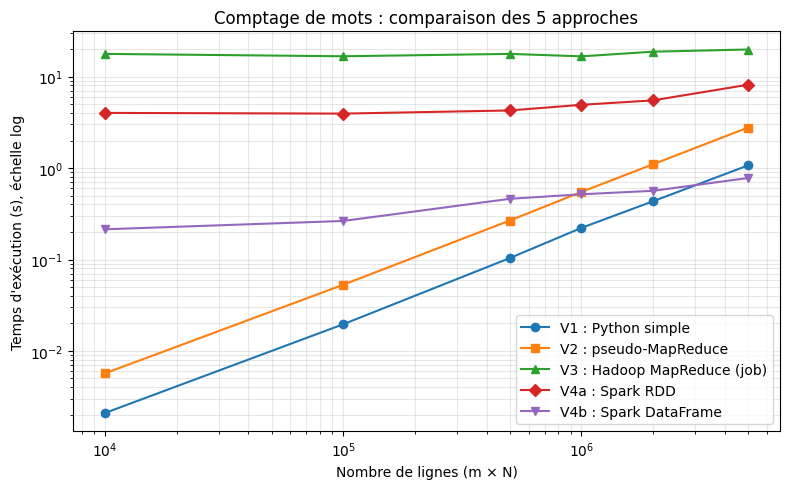

In [16]:
# Graphique 

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
for col, style, nom in [("V1 Python (s)", "o-", "V1 : Python simple"),
                        ("V2 pseudo-MR (s)", "s-", "V2 : pseudo-MapReduce"),
                        ("V3 Hadoop job (s)", "^-", "V3 : Hadoop MapReduce (job)"),
                        ("V4a Spark RDD (s)", "D-", "V4a : Spark RDD"),
                        ("V4b Spark DF (s)", "v-", "V4b : Spark DataFrame")]:
    ax.plot(resultats["lignes"], resultats[col], style, label=nom)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de lignes (m × N)")
ax.set_ylabel("Temps d'exécution (s), échelle log")
ax.set_title("Comptage de mots : comparaison des 5 approches")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("comparaison_temps.png", dpi=150)
plt.show()

### Lecture de la figure : comparaison des 5 approches

Même lecture que la figure précédente (échelles log-log), avec deux courbes supplémentaires pour Spark.

- **Spark DataFrame (violet)** a un comportement intermédiaire : la courbe est presque plate à gauche, avec
  un coût fixe d'environ 0,2 s (planification et lancement des tâches), puis elle monte lentement. Sa pente
  est nettement plus faible que celle de V1 : chaque million de lignes supplémentaire lui coûte ~3 fois
  moins cher. Elle **croise V2 vers 1 M de lignes et V1 vers 3 à 4 M de lignes**. À 5 M de lignes, c'est la
  méthode la plus rapide (0,78 s contre 1,07 s pour V1).
- **Spark RDD (rouge)** est presque plate autour de 4 à 8 s : son coût fixe est élevé, car elle doit démarrer
  des processus Python auxiliaires. Elle reste néanmoins 2 à 4 fois plus rapide que Hadoop.
- **Hadoop (vert)** reste la plus lente sur toute la plage testée.

**Interprétation.** Les cinq méthodes s'ordonnent selon deux grandeurs : leur **coût fixe** (hauteur de la
courbe à gauche) et leur **coût par ligne** (pente à droite).
- Pour de petits fichiers, seul le coût fixe compte : Python simple gagne, car il n'a presque aucun coût fixe.
- Pour de gros fichiers, c'est le coût par ligne qui compte : Spark DataFrame gagne, car il traite les données
  en parallèle sur plusieurs cœurs, dans du code compilé.
- Plus le volume augmente, plus l'écart en faveur de Spark DataFrame devrait se creuser.

In [17]:
# partitions réelles

resultats = resultats.rename(columns={"partitions Spark": "partitions RDD"})
resultats["partitions DF"] = [spark.read.text(uri(fichiers[m])).rdd.getNumPartitions() for m in resultats["m"]]
resultats.to_csv("resultats_benchmark.csv", index=False)
resultats[["m", "lignes", "partitions RDD", "partitions DF"]]

,m,lignes,partitions RDD,partitions DF
0,1,10000,2,1
1,10,100000,2,1
2,50,500000,2,1
3,100,1000000,2,2
4,200,2000000,2,4
5,500,5000000,2,8


### Lecture du tableau des partitions

Ce tableau explique les performances de Spark.
- **RDD** : `textFile` crée toujours **2 partitions** par défaut, quelle que soit la taille. Seuls 2 des
  8 cœurs travaillent.
- **DataFrame** : le nombre de partitions **augmente avec la taille** (1 → 8). Spark découpe le fichier
  en morceaux d'environ `taille / nombre de cœurs` (avec un minimum de 4 Mo). Pour le fichier de 36,6 Mo,
  cela donne 8 partitions de ~4,6 Mo : les **8 cœurs travaillent en parallèle**.

C'est ce parallélisme automatique, combiné à l'exécution dans la JVM, qui permet à Spark DataFrame de
dépasser Python simple. À titre de comparaison, notre job Hadoop n'avait qu'**un seul** mapper, car tous
nos fichiers sont plus petits qu'un bloc HDFS de 128 Mo.

## Analyse des résultats de V1, V2, et V3

Les 3 méthodes produisent exactement les mêmes comptes sur tous les fichiers.
La V1 (Python simple) est la plus rapide sur toutes les tailles testées.
La V2 (pseudo-MapReduce) est plus lente que V2. La phase map crée une paire (mot, 1) par mot, toutes stockées en mémoire, puis le shuffle les recopie dans des listes. Elle reproduit la structure de MapReduce sans en avoir le bénéfice.
La V3 (Hadoop MapReduce) est plus lent. Il ne gagne pas ici car tous les éléments du cluster tournent sur la même machine, donc il n'y a pas plus de ressources de calcul qu'en Python. De plus, tous nos fichiers
font moins de 128 Mo, qui est la taille d'un bloc HDFS, où chaque job n'a qu'un seul mapper, donc aucun
parallélisme. Hadoop n'est rentable que lorsque les données dépassent la capacité d'une seule machine
(mémoire ou disque) et que le calcul est réparti sur plusieurs nœuds. 



## Analyse des résultats Spark

Les deux variantes Spark donnent exactement les mêmes comptes que les autres méthodes.

**V4 Spark DataFrame : la plus rapide sur les gros fichiers.** Coût fixe d'environ 0,2 s
(planification du job et lancement des tâches), puis un coût marginal environ 3× plus faible que V1.
Elle dépasse V2 vers 1 M de lignes et V1 vers 3 à 4 M de lignes (0,78 s contre 1,07 s pour 5 M).
Deux raisons :
- le plan est exécuté entièrement dans la JVM, avec du code optimisé par Catalyst/Tungsten, sans
  passer par Python
- le **nombre de partitions augmente avec la taille du fichier** (1 → 8) : pour 5 M de lignes,
  Spark découpe le fichier en 8 morceaux traités en parallèle sur les 8 cœurs, alors que V1 n'utilise
  qu'un cœur et que notre job Hadoop n'avait qu'un seul mapper.

**V4 Spark RDD : lente en PySpark.** Environ 4 s même pour 10 000 lignes, et ~0,8 s par million de
lignes supplémentaire. Les lambdas Python (`split`, `(mot, 1)`, `a + b`) sont exécutées dans des
processus Python séparés : chaque ligne est sérialisée de la JVM vers Python puis renvoyée. Sous
Windows, ces processus ne peuvent pas être dupliqués par `fork` et sont relancés, d'où un coût fixe
élevé. De plus, `textFile` ne crée que 2 partitions par défaut, donc seuls 2 cœurs sur 8 travaillent.

**Spark vs Hadoop.** Même modèle map → shuffle → reduce, mais Spark DataFrame a une latence environ
80× plus faible (0,2 s contre ~17 s) : il garde les données intermédiaires en mémoire au lieu de les
écrire sur disque, et son ordonnanceur démarre ses tâches dans une JVM déjà lancée, au lieu de
demander des conteneurs à YARN.

### Exécution réelle sur YARN
Capture de l'interface du ResourceManager (http://localhost:8088) montrant les jobs `word count`
à l'état FINISHED / SUCCEEDED :

![Interface YARN](yarn_capture.png)

### Session Spark

![Interface Spark](spark_capture.png)

## Limites de l'expérience
- Cluster pseudo-distribué sur une seule machine : aucun gain de ressources par rapport à Python.
- Fichiers ≤ 36,6 Mo, donc un seul bloc HDFS et un seul mapper par job.
- Le temps Hadoop inclut un léger surcoût de `docker compose exec` (lancement de la commande dans le conteneur).
- Docker Desktop sous Windows ajoute une couche de virtualisation (VM WSL 2).
- Hadoop mesuré une seule fois par fichier (durée de chaque job) ; V1 et V2 : médiane de 3 exécutions.
- Données synthétiques à vocabulaire réduit (20 mots) : peu de clés distinctes, donc un shuffle léger.
- Spark exécuté en mode local (`local[*]`, 8 cœurs) : parallélisme sur une machine, pas de distribution réseau.
- Les mesures Hadoop ont été refaites lors de la réexécution ; elles varient de ±2 s d'une exécution à l'autre.

## Conclusion

Nous avons implémenté et testé trois méthodes de comptage de mots, validées par des tests
automatiques : les trois produisent exactement les mêmes résultats sur des fichiers de 10 000 à
5 000 000 de lignes.

| Méthode | Temps (5 M lignes) | Comportement |
|---|---|---|
| V1 : Python simple | ~1,1 s | linéaire, 1 cœur ; imbattable sur les petits fichiers |
| V2 : pseudo-MapReduce | ~2,8 s | linéaire, ~2,6× plus lente et ~2× plus de mémoire que V1 |
| V3 : Hadoop MapReduce | ~20 s (+ ~5 s de copie HDFS) | latence fixe ~17 s (YARN, JVM, disque) |
| V4a : Spark RDD (PySpark) | ~8,1 s | pénalisée par les échanges JVM ↔ Python |
| V4b : Spark DataFrame | **~0,8 s** | latence ~0,2 s, parallèle sur 8 cœurs : la plus rapide dès ~4 M lignes |

- **V2** montre la structure de MapReduce (map → shuffle → reduce), mais sans parallélisme elle ne
   fait qu'ajouter du coût : matérialiser les paires intermédiaires est cher en temps et en mémoire.
- **Hadoop** paie un coût fixe important (YARN, JVM, HDFS) qui le rend inadapté aux petits et
   moyens volumes. Sur une seule machine, il n'est jamais plus rapide que Python dans nos mesures,
   car son coût par ligne est lui aussi plus élevé.
- Le modèle MapReduce devient pertinent quand **les données dépassent ce qu'une seule machine peut
   traiter** (mémoire, disque) et que le calcul est **réparti sur plusieurs nœuds** proches des
   données. Son intérêt est le passage à l'échelle et la tolérance aux pannes, pas la vitesse
   sur de petits volumes.
- **Spark** montre ce que MapReduce peut devenir : avec l'API DataFrame, le calcul reste dans la JVM,
   en mémoire, et se parallélise automatiquement sur tous les cœurs. C'est la seule approche distribuée
   qui bat Python simple dans nos mesures, et ce, même sur une seule machine. L'API RDD avec des
   fonctions Python perd cet avantage : en PySpark, il faut privilégier les DataFrames.

In [ ]:
spark.stop()